In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('anemia Dataset.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 1421 rows, 6 columns


,Gender,Hemoglobin,MCH,MCHC,MCV,Result
0,1,15.148357,23.236254,29.838467,83.554121,0
1,0,15.830868,25.217524,27.716110,71.970087,0
2,0,9.323844,21.080395,29.708388,71.446780,1
3,0,15.661515,15.477595,30.851349,87.645449,0
4,1,14.582923,21.016822,27.905567,98.502234,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Gender      1421 non-null   int64  
 1   Hemoglobin  1421 non-null   float64
 2   MCH         1421 non-null   float64
 3   MCHC        1421 non-null   float64
 4   MCV         1421 non-null   float64
 5   Result      1421 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 66.7 KB


In [4]:
df.describe()

,Gender,Hemoglobin,MCH,MCHC,MCV,Result
count,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000
mean,0.520760,13.432429,22.922482,30.234469,85.509735,0.441239
std,0.499745,2.031305,4.006752,1.482124,9.640086,0.496710
min,0.000000,6.459035,14.897893,26.553365,68.342872,0.000000
25%,0.000000,11.799681,19.452327,29.043752,77.099197,0.000000
50%,1.000000,13.347842,22.686829,30.279667,85.328351,0.000000
75%,1.000000,15.055625,26.243159,31.446686,94.055096,1.000000
max,1.000000,18.119876,30.738765,34.076028,102.750450,1.000000


In [5]:
print("--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Duplicate Rows ---")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

--- Missing Values ---
Gender        0
Hemoglobin    0
MCH           0
MCHC          0
MCV           0
Result        0
dtype: int64

--- Duplicate Rows ---
Total Duplicate Rows: 0


--- Target Distribution (Result) ---
Result
0    794
1    627
Name: count, dtype: int64

--- Target Percentage (%) ---
Result
0    55.876144
1    44.123856
Name: proportion, dtype: float64


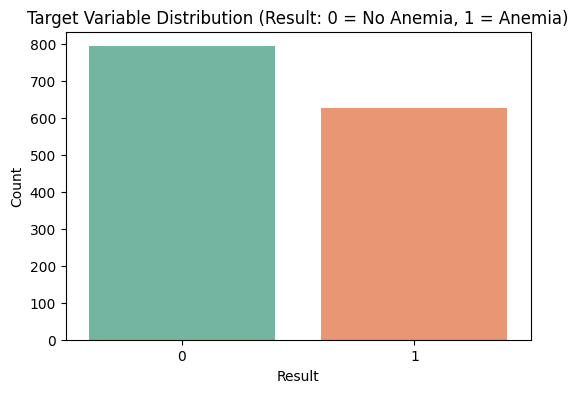

In [6]:
print("--- Target Distribution (Result) ---")
print(df['Result'].value_counts())
print("\n--- Target Percentage (%) ---")
print(df['Result'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x='Result', data=df, palette='Set2')
plt.title('Target Variable Distribution (Result: 0 = No Anemia, 1 = Anemia)')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

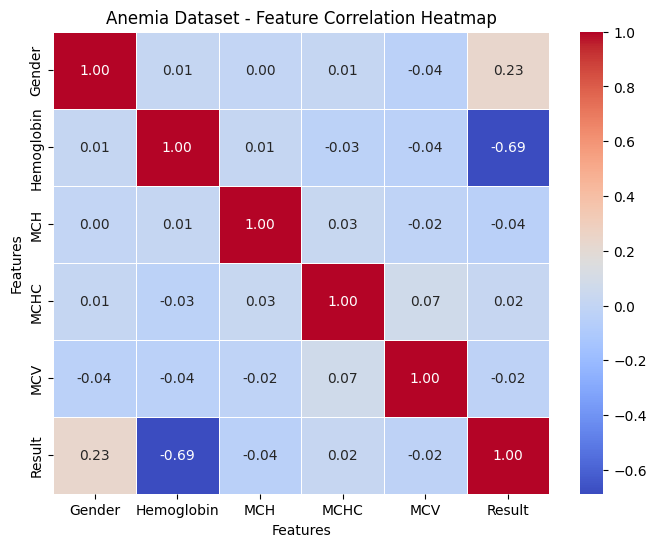

--- Correlation with Target (Result) ---
Result        1.000000
Gender        0.234006
MCHC          0.021116
MCV          -0.024521
MCH          -0.042922
Hemoglobin   -0.687049
Name: Result, dtype: float64


In [7]:
# --- Feature Correlation Analysis ---
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Anemia Dataset - Feature Correlation Heatmap')
plt.xlabel('Features')
plt.ylabel('Features')
plt.show()

print("--- Correlation with Target (Result) ---")
print(df.corr()['Result'].sort_values(ascending=False))


          Z-SCORE CALCULATION & DIRECT FEATURE STANDARDIZATION SUMMARY (|Z| > 3)
   Feature  Original Mean  Original Std Dev  Min Z  Max Z  Outliers (|Z|>3) Outlier (%)
Hemoglobin          13.43              2.03  -3.43   2.31                 4       0.28%
       MCH          22.92              4.01  -2.00   1.95                 0        0.0%
      MCHC          30.23              1.48  -2.48   2.59                 0        0.0%
       MCV          85.51              9.64  -1.78   1.79                 0        0.0%

--- Updated DataFrame Head (Features Standardized via Z-Score directly in df) ---
   Gender  Hemoglobin       MCH      MCHC       MCV  Result
0       1    0.844742  0.078311 -0.267185 -0.202863       0
1       0    1.180738  0.572794 -1.699155 -1.404515       0
2       0   -2.022633 -0.459746 -0.354951 -1.458800       1
3       0    1.097366 -1.858085  0.416213  0.221545       0
4       1    0.566382 -0.475612 -1.571328  1.347758       0


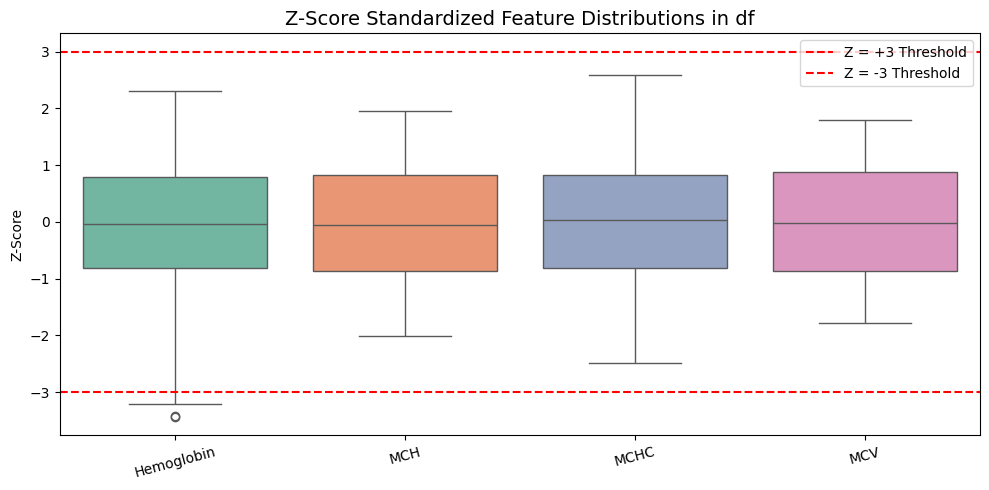

In [8]:
# --- Outlier Detection & Direct Z-Score Standardization ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Continuous numerical columns for Anemia
num_cols = [col for col in df.columns if col not in ['Gender', 'Result']]

print("=" * 70)
print("          Z-SCORE CALCULATION & DIRECT FEATURE STANDARDIZATION SUMMARY (|Z| > 3)")
print("=" * 70)

z_summary = []
for col in num_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    
    # Calculate Z-score
    z_scores = (df[col] - mean_val) / std_val
    outliers = df[abs(z_scores) > 3]
    count = len(outliers)
    pct = (count / len(df)) * 100
    
    z_summary.append({
        'Feature': col,
        'Original Mean': round(mean_val, 2),
        'Original Std Dev': round(std_val, 2),
        'Min Z': round(z_scores.min(), 2),
        'Max Z': round(z_scores.max(), 2),
        'Outliers (|Z|>3)': count,
        'Outlier (%)': f"{round(pct, 2)}%"
    })
    
    # Update numerical column directly in df with Z-Score standardized values
    df[col] = z_scores

z_df = pd.DataFrame(z_summary)
print(z_df.to_string(index=False))

print("\n--- Updated DataFrame Head (Features Standardized via Z-Score directly in df) ---")
print(df.head())

# Visualization of Z-Scores
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[num_cols], palette='Set2')
plt.xticks(range(len(num_cols)), num_cols, rotation=15)
plt.axhline(y=3, color='r', linestyle='--', label='Z = +3 Threshold')
plt.axhline(y=-3, color='r', linestyle='--', label='Z = -3 Threshold')
plt.title('Z-Score Standardized Feature Distributions in df', fontsize=14)
plt.ylabel('Z-Score')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Model Training (Logistic Regression, Random Forest & XGBoost)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

X = df.drop(columns=['Result'])
y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1136, 5)
Testing set shape: (285, 5)


In [10]:
# Logistic Regression Classifier
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train, y_train)
print("Logistic Regression Classifier successfully trained!")

# Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest Classifier successfully trained!")

# XGBoost Classifier
xgb_model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
print("XGBoost Classifier successfully trained!")

Logistic Regression Classifier successfully trained!


Random Forest Classifier successfully trained!


XGBoost Classifier successfully trained!


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89       159
           1       0.84      0.90      0.87       126

    accuracy                           0.88       285
   macro avg       0.88      0.88      0.88       285
weighted avg       0.88      0.88      0.88       285

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.89      0.90       159
           1       0.87      0.87      0.87       126

    accuracy                           0.88       285
   macro avg       0.88      0.88      0.88       285
weighted avg       0.88      0.88      0.88       285

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89       159
           1       0.86      0.86      0.86       126

    accuracy                           0.87       285
   macro avg     

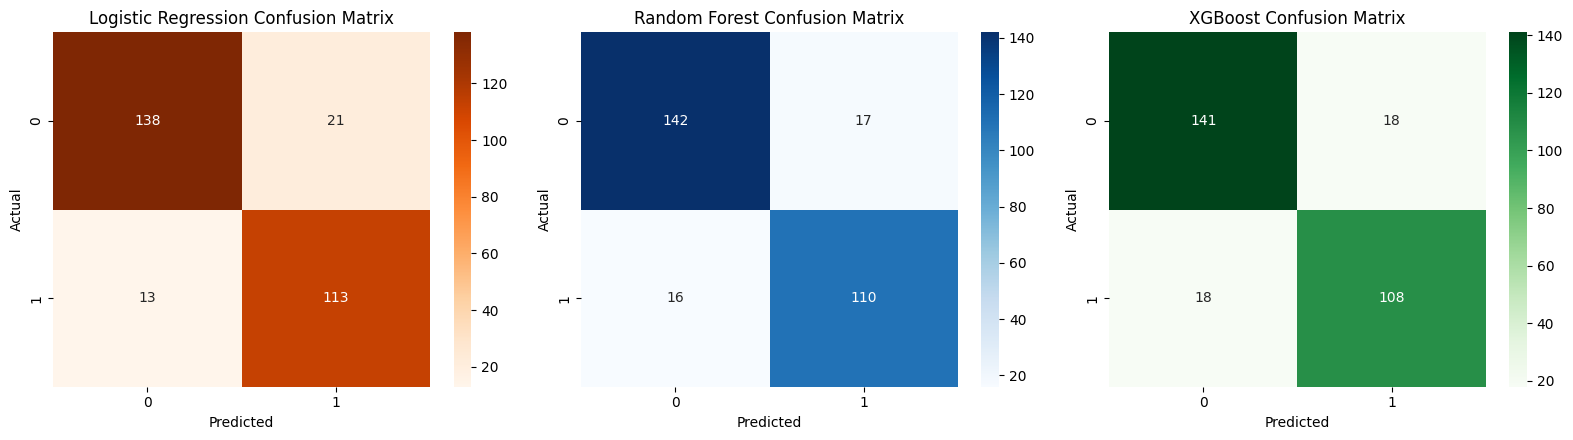

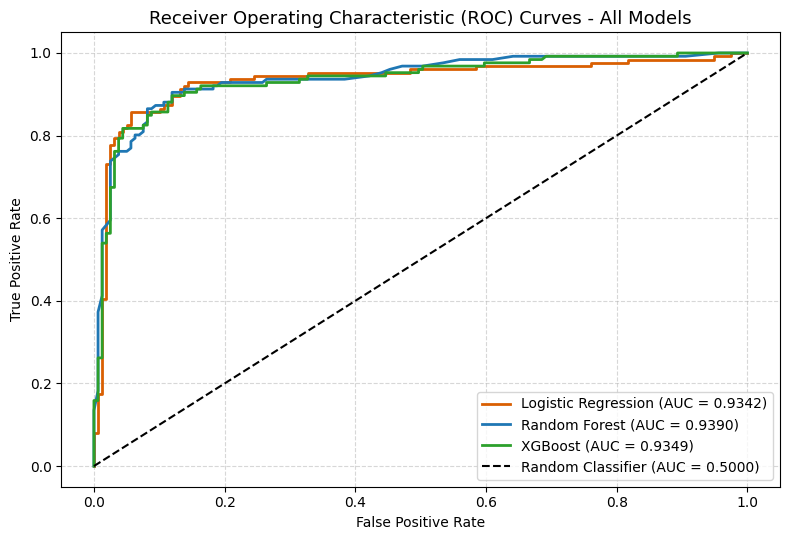

In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

# Model predictions & probabilities
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Classification Reports
print("=" * 60)
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

print("=" * 60)
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("=" * 60)
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("=" * 60)

# Confusion Matrices for All 3 Models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Oranges', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix', fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix', fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Greens', ax=axes[2])
axes[2].set_title('XGBoost Confusion Matrix', fontsize=12)
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Receiver Operating Characteristic (ROC) Comparison Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 5.5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})", color='#d95f02', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.4f})", color='#1f77b4', linewidth=2)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.4f})", color='#2ca02c', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)')
plt.title('Receiver Operating Characteristic (ROC) Curves - All Models', fontsize=13)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

           MODEL PERFORMANCE COMPARISON TABLE
              Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
Logistic Regression    0.8807     0.8433  0.8968    0.8692   0.9342
      Random Forest    0.8842     0.8661  0.8730    0.8696   0.9390
            XGBoost    0.8737     0.8571  0.8571    0.8571   0.9349


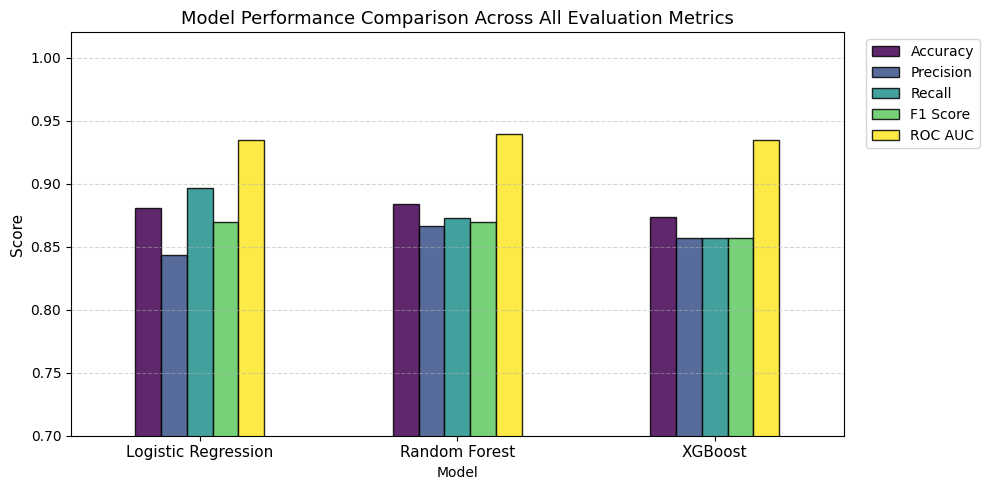


      SELECTED CHAMPION MODEL FOR CLINICAL DEPLOYMENT: RANDOM FOREST
  * Selection Criterion : Highest Test Accuracy & Overall Clinical Metric Balance
  * Accuracy            : 88.42%
  * Precision           : 86.61%
  * Recall (Sensitivity): 87.30%
  * F1-Score            : 86.96%
  * ROC AUC             : 0.9390


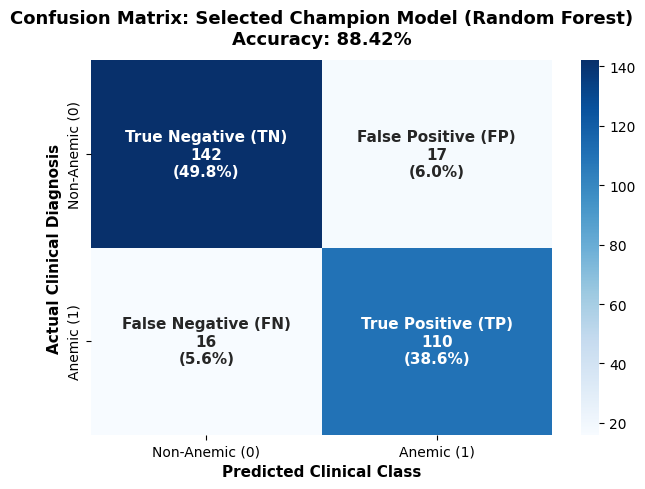


--- Champion Model Diagnostic Metric Summary ---
  * Sensitivity / Recall (True Positive Rate) : 87.30% (Ability to detect Anemic patients)
  * Specificity (True Negative Rate)          : 89.31% (Ability to detect Healthy patients)
  * Positive Predictive Value (Precision)     : 86.61%
  * Negative Predictive Value (NPV)           : 89.87%


In [12]:
# Compile performance metrics across all models
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],
    'ROC AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

print("=" * 65)
print("           MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 65)
print(comparison_df.round(4).to_string(index=False))

# Plot comparative grouped bar chart
ax = comparison_df.set_index('Model').plot(
    kind='bar', 
    figsize=(10, 5), 
    colormap='viridis', 
    edgecolor='black', 
    alpha=0.85
)
plt.title('Model Performance Comparison Across All Evaluation Metrics', fontsize=13)
plt.ylabel('Score', fontsize=11)
plt.ylim(0.70, 1.02)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# =====================================================================
# SELECTION OF THE SINGLE BEST MODEL (HIGHEST ACCURACY & EFFICIENCY)
# =====================================================================
model_candidates = {
    'Logistic Regression': (lr_model, y_pred_lr, y_prob_lr),
    'Random Forest': (rf_model, y_pred_rf, y_prob_rf),
    'XGBoost': (xgb_model, y_pred_xgb, y_prob_xgb)
}

# Automatically select the model with the highest test accuracy
best_model_row = comparison_df.sort_values(by='Accuracy', ascending=False).iloc[0]
best_model_name = best_model_row['Model']
best_model, y_pred_best, y_prob_best = model_candidates[best_model_name]

print("\n" + "=" * 70)
print(f"      SELECTED CHAMPION MODEL FOR CLINICAL DEPLOYMENT: {best_model_name.upper()}")
print("=" * 70)
print(f"  * Selection Criterion : Highest Test Accuracy & Overall Clinical Metric Balance")
print(f"  * Accuracy            : {best_model_row['Accuracy'] * 100:.2f}%")
print(f"  * Precision           : {best_model_row['Precision'] * 100:.2f}%")
print(f"  * Recall (Sensitivity): {best_model_row['Recall'] * 100:.2f}%")
print(f"  * F1-Score            : {best_model_row['F1 Score'] * 100:.2f}%")
print(f"  * ROC AUC             : {best_model_row['ROC AUC']:.4f}")
print("=" * 70)

# =====================================================================
# DEDICATED CONFUSION MATRIX & CLINICAL DIAGNOSTIC EVALUATION
# =====================================================================
cm_best = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm_best.ravel()

# Calculate clinical diagnostic metrics
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0

fig, ax = plt.subplots(figsize=(6.5, 5))
group_names = ['True Negative (TN)', 'False Positive (FP)', 'False Negative (FN)', 'True Positive (TP)']
group_counts = [f"{v:d}" for v in cm_best.flatten()]
group_percentages = [f"{v:.1%}" for v in cm_best.flatten() / np.sum(cm_best)]
labels = [f"{v1}\n{v2}\n({v3})" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

sns.heatmap(
    cm_best, 
    annot=labels, 
    fmt='', 
    cmap='Blues', 
    cbar=True,
    xticklabels=['Non-Anemic (0)', 'Anemic (1)'],
    yticklabels=['Non-Anemic (0)', 'Anemic (1)'],
    annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
plt.title(f'Confusion Matrix: Selected Champion Model ({best_model_name})\nAccuracy: {best_model_row["Accuracy"]*100:.2f}%', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Clinical Class', fontsize=11, fontweight='bold')
plt.ylabel('Actual Clinical Diagnosis', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n--- Champion Model Diagnostic Metric Summary ---")
print(f"  * Sensitivity / Recall (True Positive Rate) : {sensitivity * 100:.2f}% (Ability to detect Anemic patients)")
print(f"  * Specificity (True Negative Rate)          : {specificity * 100:.2f}% (Ability to detect Healthy patients)")
print(f"  * Positive Predictive Value (Precision)     : {ppv * 100:.2f}%")
print(f"  * Negative Predictive Value (NPV)           : {npv * 100:.2f}%")


## 9. End-to-End Clinical Decision Support Inference Pipeline (Champion Model)


In [13]:
import json

# Reference scaling parameters from raw training distribution
raw_df = pd.read_csv('anemia Dataset.csv')
num_features = ['Hemoglobin', 'MCH', 'MCHC', 'MCV']
scaling_params = {
    col: {'mean': float(raw_df[col].mean()), 'std': float(raw_df[col].std())}
    for col in num_features
}

def predict_anemia_pipeline(patient_data):
    """
    End-to-End Clinical Decision Support Inference Pipeline for Anemia.
    Exclusively utilizes the single best-performing champion model (highest accuracy).
    
    Accepts raw unscaled clinical measurements:
      - Gender: 0 (Female) or 1 (Male)
      - Hemoglobin: g/dL
      - MCH: pg
      - MCHC: g/dL
      - MCV: fL
      
    Returns a single-model diagnostic prediction, confidence probability, risk tier, and clinical recommendation.
    """
    patient_dict = patient_data.copy()
    
    # 1. Format input into DataFrame
    patient_df = pd.DataFrame([patient_dict])
    
    # 2. Standardize continuous features using baseline distribution
    standardized_df = patient_df.copy()
    for col in num_features:
        standardized_df[col] = (standardized_df[col] - scaling_params[col]['mean']) / scaling_params[col]['std']
        
    ordered_cols = ['Gender', 'Hemoglobin', 'MCH', 'MCHC', 'MCV']
    X_sample = standardized_df[ordered_cols]
    
    # 3. Predict using ONLY the single champion model (highest accuracy)
    pred = int(best_model.predict(X_sample)[0])
    prob = float(best_model.predict_proba(X_sample)[0, 1])
    
    # Clinical Risk Stratification
    if prob >= 0.70:
        risk_tier = "High Risk"
        urgency = "High (Clinical Follow-up & Ferritin/Iron Panel Recommended)"
        recommendation = "Immediate clinical consultation, serum ferritin and iron studies, and dietary/iron supplementation evaluation."
    elif prob >= 0.40:
        risk_tier = "Moderate Risk / Borderline"
        urgency = "Moderate (Monitor in 3 Months)"
        recommendation = "Repeat CBC in 3 months, assess dietary iron and vitamin B12 intake."
    else:
        risk_tier = "Low Risk"
        urgency = "Normal (Routine Monitoring)"
        recommendation = "Normal hematologic parameters. Continue routine annual wellness checks."
    
    result = {
        'Selected Model': f"{best_model_name} (Top Accuracy Champion)",
        'Model Accuracy': f"{best_model_row['Accuracy'] * 100:.2f}%",
        'Diagnostic Prediction': 'Anemic' if pred == 1 else 'Non-Anemic',
        'Anemia Risk Probability': f"{prob * 100:.2f}%",
        'Risk Tier': risk_tier,
        'Urgency Level': urgency,
        'Clinical Recommendation': recommendation
    }
    
    return result

# --- Verification with Sample Clinical Profiles ---
print("=" * 70)
print("  VERIFYING SINGLE BEST-MODEL PREDICTION PIPELINE ON PATIENT SAMPLES")
print("=" * 70)

# Sample Case 1: Healthy Patient Profile
healthy_patient = {
    'Gender': 1,           # Male
    'Hemoglobin': 15.2,    # Normal male range (13.8 - 17.2)
    'MCH': 28.0,           # Normal (27 - 33)
    'MCHC': 33.0,          # Normal (32 - 36)
    'MCV': 87.5            # Normal (80 - 100)
}

# Sample Case 2: Anemic Patient Profile (Microcytic / Low Hemoglobin)
anemic_patient = {
    'Gender': 0,           # Female
    'Hemoglobin': 8.5,     # Low female range (< 12.0)
    'MCH': 19.5,           # Low (< 27)
    'MCHC': 27.5,          # Low (< 32)
    'MCV': 68.0            # Low (< 80)
}

print("\n[Test Patient 1 - Healthy Clinical Measurements]:")
print(json.dumps(predict_anemia_pipeline(healthy_patient), indent=4))

print("\n[Test Patient 2 - Anemic Clinical Measurements]:")
print(json.dumps(predict_anemia_pipeline(anemic_patient), indent=4))


  VERIFYING SINGLE BEST-MODEL PREDICTION PIPELINE ON PATIENT SAMPLES

[Test Patient 1 - Healthy Clinical Measurements]:
{
    "Selected Model": "Random Forest (Top Accuracy Champion)",
    "Model Accuracy": "88.42%",
    "Diagnostic Prediction": "Non-Anemic",
    "Anemia Risk Probability": "8.50%",
    "Risk Tier": "Low Risk",
    "Urgency Level": "Normal (Routine Monitoring)",
    "Clinical Recommendation": "Normal hematologic parameters. Continue routine annual wellness checks."
}

[Test Patient 2 - Anemic Clinical Measurements]:
{
    "Selected Model": "Random Forest (Top Accuracy Champion)",
    "Model Accuracy": "88.42%",
    "Diagnostic Prediction": "Anemic",
    "Anemia Risk Probability": "77.50%",
    "Risk Tier": "High Risk",
    "Urgency Level": "High (Clinical Follow-up & Ferritin/Iron Panel Recommended)",
    "Clinical Recommendation": "Immediate clinical consultation, serum ferritin and iron studies, and dietary/iron supplementation evaluation."
}
